# ORBIT: run the current game model / Запусти модель из игры / 运行当前游戏模型

This notebook runs the exact model deployed in the game, selected by `source/model-release.json`. Install `requirements-notebook.txt` in Python 3.12 and run every cell, or use `python scripts/execute_notebook.py` from the repository root.

**RU.** Здесь запускается обновлённая модель из игры. Энкодер, предиктор действий и probe обучены с нуля; [полный процесс](../FROM_SCRATCH.md) доступен отдельно. [Текущие результаты](../CURRENT_MODEL.md).

**中文。** 本 notebook 运行当前游戏中的新版模型。完整的从零训练流程见 [FROM_SCRATCH.md](../FROM_SCRATCH.md)。

The original notebook is preserved under `materials/archive/`.

In [1]:
from pathlib import Path
import sys, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "planning/model.py").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
from planning.model import load_active_model, scenario, rollout, PLANS, HIT
from planning.benchmark import evaluate
print("Python:", sys.version.split()[0], "NumPy:", np.__version__)
model = load_active_model()
print("Encoder + predictor + probe loaded from separate NPZ files.")

Python: 3.12.14 NumPy: 2.1.3
Encoder + predictor + probe loaded from separate NPZ files.


## 1. Observe / Наблюдать / 观察

The planner sees two 24 × 24 images and a goal image. Simulator coordinates stay outside the planner; we use them later to check its choice.

Планировщик получает изображения, а не координаты и скорость. Числовое состояние симулятора понадобится только для проверки выбранного плана。规划器只接收图像；真实状态仅用于之后的检验。

In [2]:
failures = json.loads((root / "docs/assets/failures.json").read_text())
case = next(row for row in failures["cases"] if row["id"] == "optimistic")
scene = scenario(case["seed"], noise=case["noise"])
print("Context:", scene["frames"].shape, "Goal:", scene["goal_frame"].shape)
features = model.encode(scene["frames"])
print("Two internal representations:", features.shape)

Context: (2, 576) Goal: (576,)
Two internal representations: (2, 8)


## 2. Predict and choose / Предсказать и выбрать / 预测与选择

All 27 plans are ranked by distance to goal features. The coordinate probe helps us display predictions, but does not participate in selecting the plan. This scene was deliberately selected to show a failure, not to estimate typical accuracy.

In [3]:
best, costs, predictions = model.rank(scene["frames"], scene["goal_frame"])
actions = PLANS[best]
print("Chosen actions (-1 left, 0 coast, +1 right):", actions.tolist())
print("Predicted features:", predictions.shape)
for index in np.argsort(costs)[:5]:
    print(PLANS[index].tolist(), "feature cost =", round(float(costs[index]), 6))

Chosen actions (-1 left, 0 coast, +1 right): [1, -1, 1]
Predicted features: (27, 3, 8)
[1, -1, 1] feature cost = 0.039123
[1, 0, 1] feature cost = 0.04872
[1, -1, 0] feature cost = 0.057455
[1, 1, -1] feature cost = 0.06247
[1, 0, 0] feature cost = 0.069877


## 3. Check by executing / Проверить действием / 执行动作检验

Now the simulator executes the chosen actions. A model's own predicted cost is not the measured outcome. The oracle is a reference with privileged access to exact state and physics.

In [4]:
actual = rollout(scene["p1"], scene["v"], actions)
predicted_xy = model.decode(predictions[best])
distance = float(np.linalg.norm(actual[-1] - scene["goal"]))
all_actual = rollout(scene["p1"], scene["v"], PLANS)
oracle_distance = float(np.linalg.norm(all_actual[:, -1] - scene["goal"], axis=-1).min())
print("Predicted distance (pixels):", round(float(np.linalg.norm(predicted_xy[-1]-scene["goal"]))*23, 4))
print("Actual distance (pixels):", round(distance*23, 4), "Hit:", distance <= HIT)
print("Privileged oracle distance (pixels):", round(oracle_distance*23, 4))

Predicted distance (pixels): 0.968
Actual distance (pixels): 3.5324 Hit: False
Privileged oracle distance (pixels): 0.0699


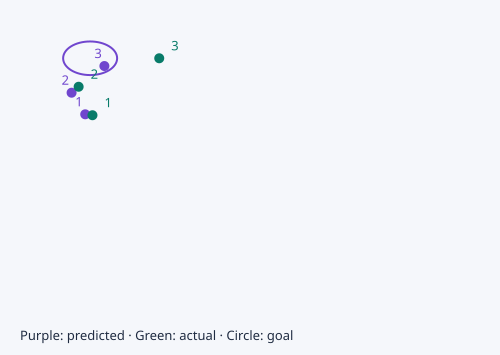

In [5]:
from IPython.display import SVG, display
# Dots are positions after each impulse; no invented continuous prediction path.
def point(p): return (25 + 450*float(p[0]), 20 + 280*float(p[1]))
svg = ['<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 500 355" role="img" aria-label="Predicted and actual positions after each action">', '<rect width="500" height="355" fill="#f5f7fb"/>']
gx, gy = point(scene["goal"])
svg.append(f'<ellipse cx="{gx}" cy="{gy}" rx="{450*HIT}" ry="{280*HIT}" fill="none" stroke="#7046ce" stroke-width="2"/>')
for positions, color, offset in [(predicted_xy, '#7046ce', -10), (actual, '#087b69', 12)]:
    for step, p in enumerate(positions, 1):
        x, y = point(p)
        svg.append(f'<circle cx="{x}" cy="{y}" r="5" fill="{color}"/><text x="{x+offset}" y="{y-8}" fill="{color}" font-family="sans-serif" font-size="13">{step}</text>')
svg.append('<text x="20" y="340" fill="#202c42" font-family="sans-serif" font-size="13">Purple: predicted · Green: actual · Circle: goal</text></svg>')
display(SVG(''.join(svg)))

## 4. A fresh small benchmark / Небольшая новая проверка / 小规模重新评测

The next cell actually evaluates the current model on 256 scenes separate from the 3,072-scene selection benchmark. The sample is small; its intervals describe scene sampling only. Полный опубликованный тест и условия: [CURRENT_MODEL.md](../CURRENT_MODEL.md).

In [6]:
small_report = evaluate(model, seeds=[70001, 70002], per_seed=128)
for name, result in small_report["aggregate"].items():
    low, high = result["hit_ci95_wilson"]
    print(f"{name:18s} hit={100*result['hit_rate']:5.1f}%  95% CI=[{100*low:.1f}, {100*high:.1f}]  distance={result['mean_distance_px']:.3f} px")

model              hit= 71.9%  95% CI=[66.1, 77.0]  distance=0.883 px
random             hit= 19.1%  95% CI=[14.8, 24.4]  distance=4.380 px
no_push            hit= 23.4%  95% CI=[18.7, 29.0]  distance=3.421 px
shuffled_actions   hit= 18.8%  95% CI=[14.4, 24.0]  distance=4.358 px
oracle             hit=100.0%  95% CI=[98.5, 100.0]  distance=0.195 px


## 5. Published larger measurements / Полные измерения / 完整评测

This cell reads the published report for three independent full temporal JEPA trainings. It does not rerun that larger evaluation. The deployed model was selected as the best of these three on the normal-condition benchmark; this is not an independent post-selection test.

In [7]:
release = json.loads((root / "source/model-release.json").read_text())
report = json.loads((root / release["benchmark"]).read_text())
print("Protocol:", report["protocol"], "scenes per condition:", report["per_seed"]*len(report["seeds"]))
for name, result in report["models"].items():
    normal = result["conditions"]["normal"]["aggregate"]["model"]
    print(name, f"{100*normal['hit_rate']:.2f}% hits", "(current game)" if name == release["benchmarkModel"] else "")

Protocol: orbit-v04-eval scenes per condition: 3072
temporal-42 68.65% hits 
temporal-43 67.51% hits 
temporal-44 74.45% hits (current game)


## Train and experiment / Обучение и эксперименты / 训练与实验

Install `requirements-training.txt`, then run the complete recovered recipe:

```sh
python -m planning.original_training --seed 44 --action-seed 31005 --out runs/my-model
python -m planning.benchmark --no-released --model-dirs runs/my-model --out reports/my-comparison.json
```

The output directory must be new. Every network starts from random initialization. The coordinate probe is supervised only for display; it never selects plans. See [FROM_SCRATCH.md](../FROM_SCRATCH.md) and the [training notebook](ORBIT_From_Scratch.ipynb) for the full method and platform limitations.

**Try:** change the scene and observation noise, then compare predicted and actual outcomes. This toy task does not establish real-world robotics capability or superiority to LLMs.

**RU.** Меняйте сцену и шум, сравнивайте прогноз и настоящее движение. Теперь всё обучение можно повторить с нуля.

**中文。** 可以改变场景和噪声，比较预测与实际结果。完整训练过程现已可以从零运行。